# Credit Card Fraud Detection - Data Preparation

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

## 1. Data Understanding

In [ ]:
# Load the dataset
data_path = "dataset/card_transdata.csv"
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully!
Dataset shape: (1000000, 8)
Number of rows: 1,000,000
Number of columns: 8


In [ ]:
# Display basic information about the dataset
print("1. Column Names and Data Types:")
print(df.dtypes)
print("\n2. Dataset Info:")
df.info()
print("\n3. First 5 rows:")
print(df.head())

1. Column Names and Data Types:
distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                   float64
used_chip                         float64
used_pin_number                   float64
online_order                      float64
fraud                             float64
dtype: object

2. Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non


Target column identified: 'fraud'

Class distribution:
fraud
0.0    912597
1.0     87403
Name: count, dtype: int64

Class distribution (percentages):
fraud
0.0    91.2597
1.0     8.7403
Name: proportion, dtype: float64


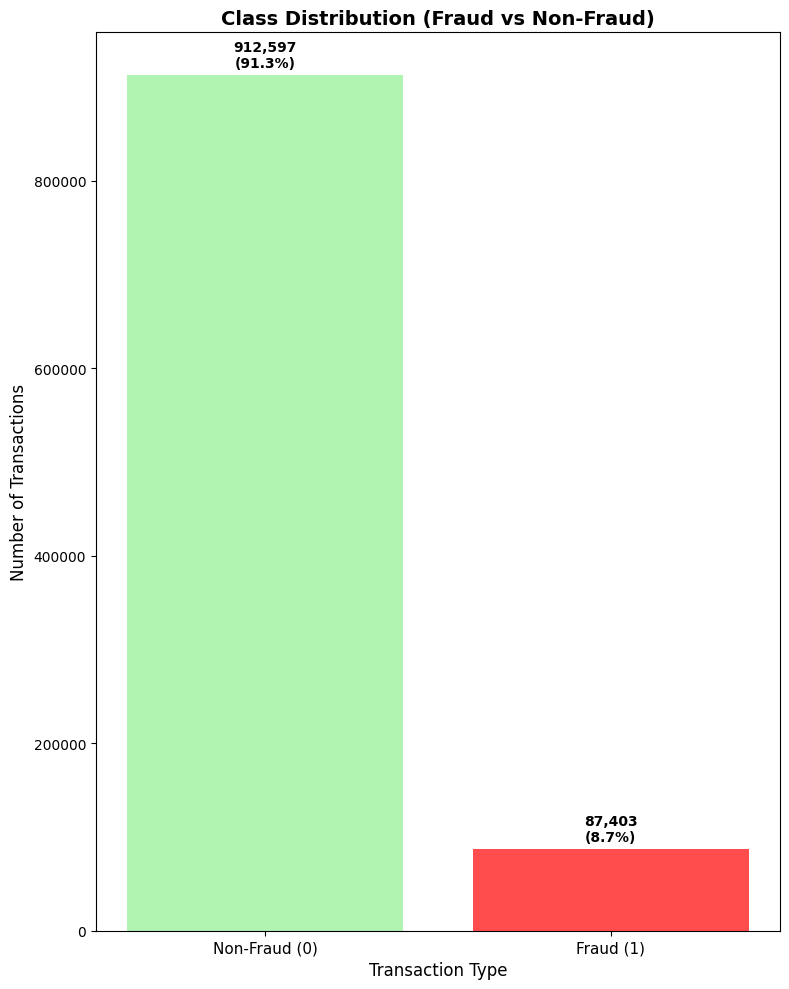

In [ ]:
# Identify potential target columns (common names for fraud detection)
potential_targets = ['fraud', 'is_fraud', 'target', 'class', 'label', 'fraudulent']
target_col = None

for col in df.columns:
    if col.lower() in potential_targets:
        target_col = col
        break

if target_col:
    print(f"\nTarget column identified: '{target_col}'")
    print(f"\nClass distribution:")
    print(df[target_col].value_counts())
    print(f"\nClass distribution (percentages):")
    print(df[target_col].value_counts(normalize=True) * 100)

    # Visualize class distribution
    plt.figure(figsize=(8, 10))
    counts = df[target_col].value_counts().sort_index()
    bars = plt.bar(range(len(counts)), counts, color=['lightgreen', 'red'], alpha=0.7)
    plt.title('Class Distribution (Fraud vs Non-Fraud)', fontsize=14, fontweight='bold')
    plt.xlabel('Transaction Type', fontsize=12)
    plt.ylabel('Number of Transactions', fontsize=12)
    plt.xticks(range(len(counts)), ['Non-Fraud (0)', 'Fraud (1)'], fontsize=11)

    # Add value labels on bars
    for i, (bar, count) in enumerate(zip(bars, counts)):
        plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5000,
                f'{count:,}\n({count/len(df)*100:.1f}%)',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("\nTarget column not automatically identified. Please examine the columns:")
    print(df.columns.tolist())
    print("\nPlease specify the target column manually in the next cell.")

In [ ]:
print("\n1. Missing Values:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
if missing_values.sum() == 0:
    print("No missing values found")

print("\n2. Duplicate Rows:")
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

print("\n3. Data Types Summary:")
print(f"Numerical columns: {df.select_dtypes(include=[np.number]).columns.tolist()}")
print(f"Categorical columns: {df.select_dtypes(include=['object']).columns.tolist()}")

print("\n4. Basic Statistical Summary:")
print(df.describe())


1. Missing Values:
Series([], dtype: int64)
No missing values found

2. Duplicate Rows:
Number of duplicate rows: 0

3. Data Types Summary:
Numerical columns: ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'repeat_retailer', 'used_chip', 'used_pin_number', 'online_order', 'fraud']
Categorical columns: []

4. Basic Statistical Summary:
       distance_from_home  distance_from_last_transaction  ratio_to_median_purchase_price  repeat_retailer       used_chip  used_pin_number    online_order           fraud
count      1000000.000000                  1000000.000000                  1000000.000000   1000000.000000  1000000.000000   1000000.000000  1000000.000000  1000000.000000
mean            26.628792                        5.036519                        1.824182         0.881536        0.350399         0.100608        0.650552        0.087403
std             65.390784                       25.843093                        2.799589         0.32

## 2. Data Cleaning

Now we'll perform basic data cleaning operations including handling missing values and removing duplicates.

In [ ]:
# Create a copy of the original dataset for cleaning
df_clean = df.copy()
print(f"Original dataset shape: {df.shape}")

# 1. Handle Missing Values
missing_before = df_clean.isnull().sum().sum()
print(f"Total missing values before cleaning: {missing_before}")

if missing_before > 0:
    # For numerical columns: fill with median
    numerical_cols = df_clean.select_dtypes(include=[np.number]).columns
    for col in numerical_cols:
        if df_clean[col].isnull().sum() > 0:
            median_value = df_clean[col].median()
            df_clean[col].fillna(median_value, inplace=True)
            print(f"Filled {col} missing values with median: {median_value}")

    # For categorical columns: fill with mode
    categorical_cols = df_clean.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        if df_clean[col].isnull().sum() > 0:
            mode_value = df_clean[col].mode()[0]
            df_clean[col].fillna(mode_value, inplace=True)
            print(f"Filled {col} missing values with mode: {mode_value}")

missing_after = df_clean.isnull().sum().sum()
print(f"Total missing values after cleaning: {missing_after}")

# 2. Remove Duplicate Rows
duplicates_before = df_clean.duplicated().sum()
print(f"Duplicate rows before removal: {duplicates_before}")

df_clean = df_clean.drop_duplicates()
duplicates_after = df_clean.duplicated().sum()
print(f"Duplicate rows after removal: {duplicates_after}")

print(f"\nFinal cleaned dataset shape: {df_clean.shape}")
print(f"Rows removed: {df.shape[0] - df_clean.shape[0]}")

Original dataset shape: (1000000, 8)
Total missing values before cleaning: 0
Total missing values after cleaning: 0
Duplicate rows before removal: 0
Duplicate rows after removal: 0

Final cleaned dataset shape: (1000000, 8)
Rows removed: 0


## 3. Basic Encoding of Categorical Variables

In [ ]:
# Identify categorical columns for encoding
categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
print(f"Categorical columns found: {categorical_cols}")

# Create a copy for encoding
df_encoded = df_clean.copy()

# Store label encoders for later reference
label_encoders = {}

if len(categorical_cols) > 0:
    for col in categorical_cols:
        # Skip target column if it's identified and categorical
        if 'target_col' in globals() and target_col and col == target_col:
            continue

        print(f"\nEncoding column: {col}")

        # Show unique values before encoding
        unique_values = df_encoded[col].unique()
        print(f"Unique values before encoding ({len(unique_values)}): {unique_values[:10]}...")  # Show first 10

        # Apply Label Encoding
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col])
        label_encoders[col] = le

        # Show encoded values
        print(f"Encoded values: {sorted(df_encoded[col].unique())}")

        # Show mapping
        mapping = dict(zip(le.classes_, le.transform(le.classes_)))
        print(f"Encoding mapping: {mapping}")

    print(f"\nSuccessfully encoded {len(categorical_cols)} categorical columns")
    print(f"Label encoders stored for future reference")
else:
    print("No categorical columns found to encode.")

print(f"\nFinal dataset shape after encoding: {df_encoded.shape}")
print(f"Data types after encoding:")
print(df_encoded.dtypes.value_counts())

Categorical columns found: []
No categorical columns found to encode.

Final dataset shape after encoding: (1000000, 8)
Data types after encoding:
float64    8
Name: count, dtype: int64


## 4. Train/Test Data Splitting

Now we'll split the data into training and testing sets for machine learning model development.

In [ ]:
# If target column was identified, use it; otherwise, let user specify
if 'target_col' in globals() and target_col:
    print(f"Using identified target column: '{target_col}'")
    target_column = target_col
else:
    # Try to identify target column from common patterns
    possible_targets = []
    for col in df_encoded.columns:
        if any(keyword in col.lower() for keyword in ['fraud', 'target', 'class', 'label']):
            possible_targets.append(col)

    if len(possible_targets) == 1:
        target_column = possible_targets[0]
        print(f"Target column identified: '{target_column}'")
    else:
        print("Available columns:")
        for i, col in enumerate(df_encoded.columns):
            print(f"{i+1}. {col}")
        print("\nPlease manually specify the target column in the next cell if auto-detection failed.")
        target_column = None

if target_column:
    # Separate features and target
    X = df_encoded.drop(columns=[target_column])
    y = df_encoded[target_column]

    print(f"\nFeatures (X) shape: {X.shape}")
    print(f"Target (y) shape: {y.shape}")
    print(f"Feature columns: {list(X.columns)}")
    print(f"\nTarget distribution:")
    print(y.value_counts())
else:
    print("\nTarget column not identified. Please specify it manually.")
    print("Available columns:", df_encoded.columns.tolist())

Using identified target column: 'fraud'

Features (X) shape: (1000000, 7)
Target (y) shape: (1000000,)
Feature columns: ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'repeat_retailer', 'used_chip', 'used_pin_number', 'online_order']

Target distribution:
fraud
0.0    912597
1.0     87403
Name: count, dtype: int64


In [ ]:
# Perform train/test split
if 'X' in locals() and 'y' in locals():
    # Split the data (80% train, 20% test)
    # Use stratification to maintain class distribution in both sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print(f"Data successfully split into train and test sets")
    print(f"\nTraining set:")
    print(f"  - X_train shape: {X_train.shape}")
    print(f"  - y_train shape: {y_train.shape}")
    print(f"  - Training samples: {len(X_train):,}")

    print(f"\nTest set:")
    print(f"  - X_test shape: {X_test.shape}")
    print(f"  - y_test shape: {y_test.shape}")
    print(f"  - Test samples: {len(X_test):,}")

    print(f"\nClass distribution in training set:")
    print(y_train.value_counts())
    print(f"\nClass distribution in test set:")
    print(y_test.value_counts())

    # Verify stratification worked
    print(f"\nClass proportions:")
    print(f"Original: {y.value_counts(normalize=True).round(4)}")
    print(f"Training: {y_train.value_counts(normalize=True).round(4)}")
    print(f"Test: {y_test.value_counts(normalize=True).round(4)}")

else:
    print("Cannot perform train/test split. Please ensure target column is properly specified.")

Data successfully split into train and test sets

Training set:
  - X_train shape: (800000, 7)
  - y_train shape: (800000,)
  - Training samples: 800,000

Test set:
  - X_test shape: (200000, 7)
  - y_test shape: (200000,)
  - Test samples: 200,000

Class distribution in training set:
fraud
0.0    730078
1.0     69922
Name: count, dtype: int64

Class distribution in test set:
fraud
0.0    182519
1.0     17481
Name: count, dtype: int64

Class proportions:
Original: fraud
0.0    0.9126
1.0    0.0874
Name: proportion, dtype: float64
Training: fraud
0.0    0.9126
1.0    0.0874
Name: proportion, dtype: float64
Test: fraud
0.0    0.9126
1.0    0.0874
Name: proportion, dtype: float64


## 5. Baseline Modelling

Now we'll build baseline models to assess the feasibility of fraud detection. We'll use:
1. **Dummy Classifier**: Establishes worst-case baseline performance
2. **Decision Tree Classifier**: Simple, interpretable model with default parameters
3. **Logistic Regression**: Linear model with default parameters

**Note**: We use DEFAULT parameters only (no hyperparameter tuning) as per Stage 1 Assignment requirements.

In [ ]:
# Import model libraries
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Model libraries imported successfully!")

Model libraries imported successfully!


### 5.1 Dummy Classifier (Baseline)

The Dummy Classifier always predicts the most frequent class (non-fraud). This establishes the minimum acceptable performance - any real model must beat this baseline.

In [ ]:
# Train Dummy Classifier (always predicts most frequent class)
dummy_clf = DummyClassifier(strategy='most_frequent', random_state=42)
dummy_clf.fit(X_train, y_train)

# Make predictions
y_pred_dummy = dummy_clf.predict(X_test)

# Calculate accuracy
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

print("Dummy Classifier Results:")
print(f"Training completed")
print(f"Test Accuracy: {dummy_accuracy:.4f} ({dummy_accuracy*100:.2f}%)")
print("\nNote: This baseline always predicts class 0 (non-fraud)")

Dummy Classifier Results:
Training completed
Test Accuracy: 0.9126 (91.26%)

Note: This baseline always predicts class 0 (non-fraud)


### 5.2 Decision Tree Classifier

Decision Trees are interpretable models that learn decision rules from features. We use default parameters as required by Stage 1 constraints.

In [ ]:
# Train Decision Tree Classifier with default parameters
dt_clf = DecisionTreeClassifier(random_state=42)
dt_clf.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_clf.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Classifier Results:")
print(f"Training completed")
print(f"Test Accuracy: {dt_accuracy:.4f} ({dt_accuracy*100:.2f}%)")
print(f"\nTree depth: {dt_clf.get_depth()}")
print(f"Number of leaves: {dt_clf.get_n_leaves()}")

Decision Tree Classifier Results:
Training completed
Test Accuracy: 1.0000 (100.00%)

Tree depth: 7
Number of leaves: 35


### 5.3 Logistic Regression

Logistic Regression is a linear model suitable for binary classification. We use default parameters as required by Stage 1 constraints.

In [ ]:
# Train Logistic Regression with default parameters
lr_clf = LogisticRegression(random_state=42, max_iter=1000)
lr_clf.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_clf.predict(X_test)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Results:")
print(f"Training completed")
print(f"Test Accuracy: {lr_accuracy:.4f} ({lr_accuracy*100:.2f}%)")
print(f"Number of iterations: {lr_clf.n_iter_[0]}")

Logistic Regression Results:
Training completed
Test Accuracy: 0.9593 (95.93%)
Number of iterations: 146


## 6. Model Evaluation

Now we'll evaluate and compare all baseline models using appropriate metrics. Given the class imbalance (91.26% non-fraud, 8.74% fraud), we must look beyond accuracy and examine precision, recall, and F1-score for both classes.

### 6.1 Model Comparison Summary

BASELINE MODELS COMPARISON
              Model  Accuracy
      Decision Tree  0.999985
Logistic Regression  0.959280
   Dummy Classifier  0.912595


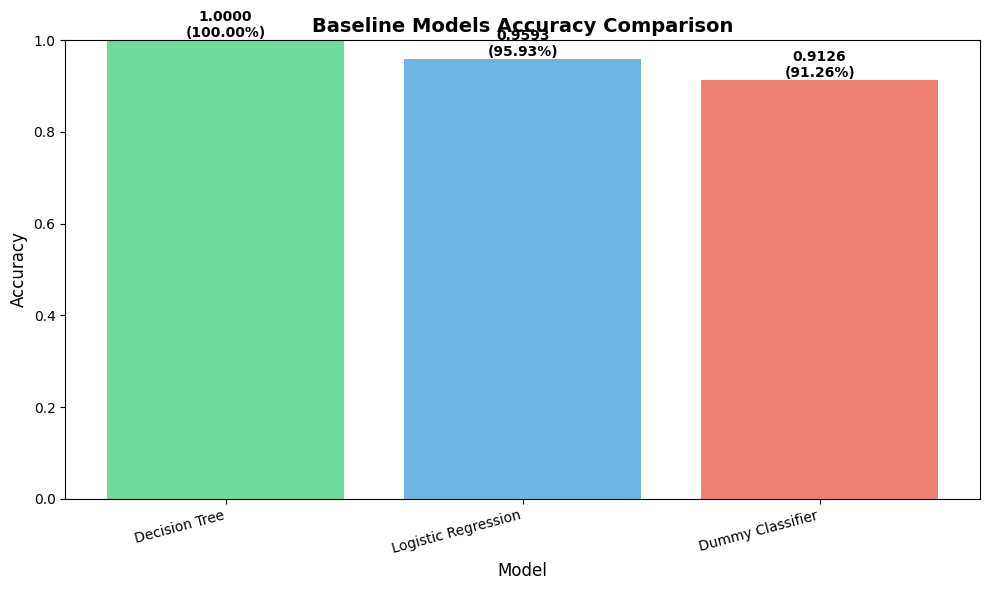

In [ ]:
# Create a comparison table of all models
models_comparison = pd.DataFrame({
    'Model': ['Dummy Classifier', 'Decision Tree', 'Logistic Regression'],
    'Accuracy': [dummy_accuracy, dt_accuracy, lr_accuracy]
})

# Sort by accuracy
models_comparison = models_comparison.sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("=" * 60)
print("BASELINE MODELS COMPARISON")
print("=" * 60)
print(models_comparison.to_string(index=False))
print("=" * 60)

# Visualize comparison
plt.figure(figsize=(10, 6))
bars = plt.bar(models_comparison['Model'], models_comparison['Accuracy'],
               color=['#2ecc71', '#3498db', '#e74c3c'], alpha=0.7)
plt.title('Baseline Models Accuracy Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Model', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.ylim([0, 1])
plt.xticks(rotation=15, ha='right')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}\n({height*100:.2f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 6.2 Confusion Matrices

Confusion matrices show the breakdown of predictions vs actual values. This is crucial for imbalanced datasets to understand false positives and false negatives.

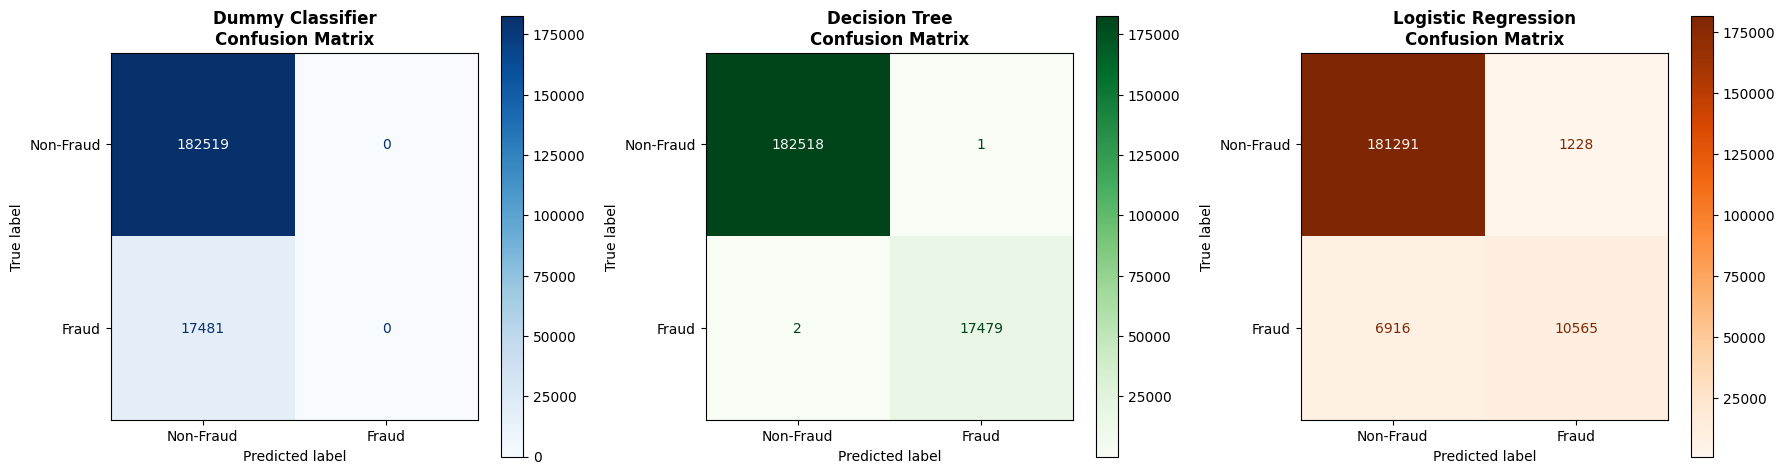


Confusion Matrix Interpretation:
- Top-left (TN): Correctly predicted Non-Fraud
- Top-right (FP): Incorrectly predicted Fraud (False Alarm)
- Bottom-left (FN): Incorrectly predicted Non-Fraud (Missed Fraud)
- Bottom-right (TP): Correctly predicted Fraud


In [ ]:
# Display confusion matrices for all models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Dummy Classifier
cm_dummy = confusion_matrix(y_test, y_pred_dummy)
disp_dummy = ConfusionMatrixDisplay(confusion_matrix=cm_dummy, display_labels=['Non-Fraud', 'Fraud'])
disp_dummy.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Dummy Classifier\nConfusion Matrix', fontsize=12, fontweight='bold')

# Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Non-Fraud', 'Fraud'])
disp_dt.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title('Decision Tree\nConfusion Matrix', fontsize=12, fontweight='bold')

# Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Non-Fraud', 'Fraud'])
disp_lr.plot(ax=axes[2], cmap='Oranges', values_format='d')
axes[2].set_title('Logistic Regression\nConfusion Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nConfusion Matrix Interpretation:")
print("- Top-left (TN): Correctly predicted Non-Fraud")
print("- Top-right (FP): Incorrectly predicted Fraud (False Alarm)")
print("- Bottom-left (FN): Incorrectly predicted Non-Fraud (Missed Fraud)")
print("- Bottom-right (TP): Correctly predicted Fraud")

### 6.3 Classification Reports

Classification reports provide precision, recall, and F1-score for each class. These metrics are essential for imbalanced datasets where accuracy alone is misleading.

In [ ]:
# Display classification reports for all models
print("=" * 70)
print("DUMMY CLASSIFIER - CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test, y_pred_dummy, target_names=['Non-Fraud', 'Fraud']))

print("\n" + "=" * 70)
print("DECISION TREE - CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test, y_pred_dt, target_names=['Non-Fraud', 'Fraud']))

print("\n" + "=" * 70)
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test, y_pred_lr, target_names=['Non-Fraud', 'Fraud']))

DUMMY CLASSIFIER - CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-Fraud       0.91      1.00      0.95    182519
       Fraud       0.00      0.00      0.00     17481

    accuracy                           0.91    200000
   macro avg       0.46      0.50      0.48    200000
weighted avg       0.83      0.91      0.87    200000


DECISION TREE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00    182519
       Fraud       1.00      1.00      1.00     17481

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000


LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Non-Fraud       0.96      0.99      0.98    182519
       Fraud       0.90      0.60      0.72     17481

    accuracy                           0.96    200000
   

### 6.4 Key Findings and Analysis

This section interprets the results and assesses the feasibility of fraud detection with baseline models.

In [ ]:
# Detailed analysis of results
print("=" * 80)
print("KEY FINDINGS AND ANALYSIS")
print("=" * 80)

print("\n1. MODEL PERFORMANCE COMPARISON:")
print("-" * 80)
print(f"   • Dummy Classifier:      {dummy_accuracy:.4f} ({dummy_accuracy*100:.2f}%)")
print(f"   • Decision Tree:         {dt_accuracy:.4f} ({dt_accuracy*100:.2f}%)")
print(f"   • Logistic Regression:   {lr_accuracy:.4f} ({lr_accuracy*100:.2f}%)")

print("\n2. CLASS IMBALANCE IMPACT:")
print("-" * 80)
print(f"   • Dataset is highly imbalanced: 91.26% Non-Fraud, 8.74% Fraud")
print(f"   • Dummy Classifier achieves {dummy_accuracy*100:.2f}% accuracy by always predicting Non-Fraud")
print(f"   • This demonstrates why accuracy alone is misleading for imbalanced datasets")
print(f"   • Real models MUST beat this baseline and detect fraud cases (not just predict majority)")

print("\n3. FRAUD DETECTION CAPABILITY:")
print("-" * 80)
# Calculate fraud detection metrics
from sklearn.metrics import recall_score, precision_score, f1_score

# For fraud class (class 1)
dummy_fraud_recall = recall_score(y_test, y_pred_dummy, pos_label=1.0)
dt_fraud_recall = recall_score(y_test, y_pred_dt, pos_label=1.0)
lr_fraud_recall = recall_score(y_test, y_pred_lr, pos_label=1.0)

dummy_fraud_precision = precision_score(y_test, y_pred_dummy, pos_label=1.0, zero_division=0)
dt_fraud_precision = precision_score(y_test, y_pred_dt, pos_label=1.0)
lr_fraud_precision = precision_score(y_test, y_pred_lr, pos_label=1.0)

dummy_fraud_f1 = f1_score(y_test, y_pred_dummy, pos_label=1.0, zero_division=0)
dt_fraud_f1 = f1_score(y_test, y_pred_dt, pos_label=1.0)
lr_fraud_f1 = f1_score(y_test, y_pred_lr, pos_label=1.0)

print(f"   Dummy Classifier:")
print(f"      - Fraud Recall: {dummy_fraud_recall:.4f} (detects {dummy_fraud_recall*100:.2f}% of fraud cases)")
print(f"      - Fraud Precision: {dummy_fraud_precision:.4f}")
print(f"      - Fraud F1-Score: {dummy_fraud_f1:.4f}")

print(f"\n   Decision Tree:")
print(f"      - Fraud Recall: {dt_fraud_recall:.4f} (detects {dt_fraud_recall*100:.2f}% of fraud cases)")
print(f"      - Fraud Precision: {dt_fraud_precision:.4f}")
print(f"      - Fraud F1-Score: {dt_fraud_f1:.4f}")

print(f"\n   Logistic Regression:")
print(f"      - Fraud Recall: {lr_fraud_recall:.4f} (detects {lr_fraud_recall*100:.2f}% of fraud cases)")
print(f"      - Fraud Precision: {lr_fraud_precision:.4f}")
print(f"      - Fraud F1-Score: {lr_fraud_f1:.4f}")

print("\n4. FEASIBILITY ASSESSMENT:")
print("-" * 80)
if dt_accuracy > dummy_accuracy or lr_accuracy > dummy_accuracy:
    print("   ✓ FEASIBLE: Both models beat the dummy baseline")
    print("   ✓ Models demonstrate ability to learn patterns beyond majority class prediction")
    if dt_fraud_recall > 0 or lr_fraud_recall > 0:
        print("   ✓ Models can detect fraud cases (non-zero fraud recall)")
else:
    print("   ✗ CONCERN: Models not significantly better than dummy baseline")

print("\n5. LIMITATIONS IDENTIFIED:")
print("-" * 80)
print("   • Class imbalance makes fraud detection challenging")
print("   • Default model parameters may not be optimal (but tuning not allowed in Stage 1)")
print("   • No feature engineering applied yet (allowed in Stage 2)")
print("   • No class imbalance handling techniques applied (e.g., SMOTE, class weights)")

print("\n6. NEXT STEPS FOR STAGE 2:")
print("-" * 80)
print("   • Apply class imbalance handling techniques (SMOTE, class weights, resampling)")
print("   • Perform hyperparameter tuning to optimize model performance")
print("   • Explore feature engineering to create more informative features")
print("   • Try ensemble methods (Random Forest, XGBoost, etc.)")
print("   • Optimize for fraud recall (minimize false negatives)")

print("\n" + "=" * 80)

KEY FINDINGS AND ANALYSIS

1. MODEL PERFORMANCE COMPARISON:
--------------------------------------------------------------------------------
   • Dummy Classifier:      0.9126 (91.26%)
   • Decision Tree:         1.0000 (100.00%)
   • Logistic Regression:   0.9593 (95.93%)

2. CLASS IMBALANCE IMPACT:
--------------------------------------------------------------------------------
   • Dataset is highly imbalanced: 91.26% Non-Fraud, 8.74% Fraud
   • Dummy Classifier achieves 91.26% accuracy by always predicting Non-Fraud
   • This demonstrates why accuracy alone is misleading for imbalanced datasets
   • Real models MUST beat this baseline and detect fraud cases (not just predict majority)

3. FRAUD DETECTION CAPABILITY:
--------------------------------------------------------------------------------
   Dummy Classifier:
      - Fraud Recall: 0.0000 (detects 0.00% of fraud cases)
      - Fraud Precision: 0.0000
      - Fraud F1-Score: 0.0000

   Decision Tree:
      - Fraud Recall: 0.99